# Day 01 Lab — Build Your First Machine Learning Model with Python
**Dataset:** Iris flower classification (built into scikit-learn) — 150 flowers, 4 measurements in cm, 3 species.

**Goal:** predict the species of an Iris flower from its measurements, then evaluate how well the model works on unseen data.

**Name:**  
**Roll number:**  
**Date:** 23 October 2026

---
# Lab Hour 1 — Environment and Data Exploration
## Step 1: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.0


## Step 2: Load Iris and convert it to a DataFrame

In [2]:
iris = load_iris()
print(iris.keys())
print("Features:", iris.feature_names)
print("Classes: ", list(iris.target_names))

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes:  ['setosa', 'versicolor', 'virginica']


In [3]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## Step 3: Understand the data

In [4]:
print(df.shape)   # rows, columns
df.info()

(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB


In [5]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
print(df["species"].value_counts())
print()
print(df.isnull().sum())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [7]:
df.groupby("species", observed=True).mean()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


## Step 4: Features and target
| Role | Column(s) |
| --- | --- |
| Features (X) | sepal length, sepal width, petal length, petal width (cm) |
| Target (y) | species |
| Problem type | Multiclass classification (supervised) |

## Step 5: Visualise
### Feature distributions

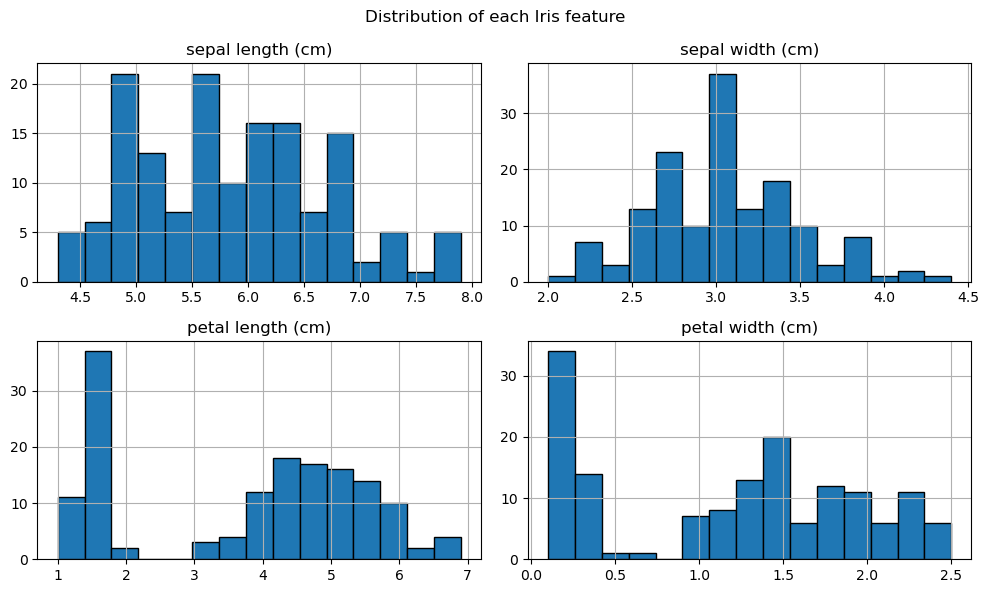

In [8]:
df.hist(figsize=(10, 6), bins=15, edgecolor="black")
plt.suptitle("Distribution of each Iris feature")
plt.tight_layout()
plt.show()

### Petal length vs petal width by species

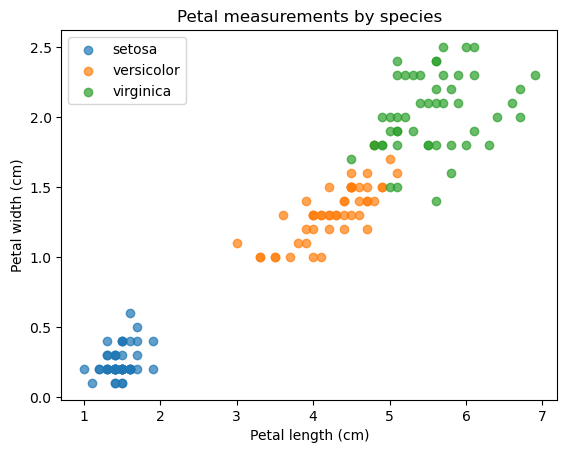

In [9]:
colors = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}

for species, group in df.groupby("species", observed=True):
    plt.scatter(group["petal length (cm)"], group["petal width (cm)"],
                label=species, color=colors[species], alpha=0.7)
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal measurements by species")
plt.legend()
plt.show()

### Petal length by species

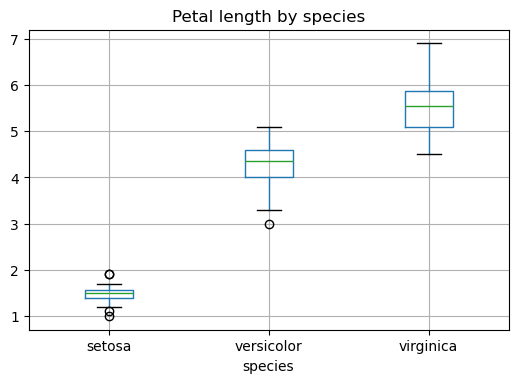

In [10]:
df.boxplot(column="petal length (cm)", by="species", figsize=(6, 4))
plt.suptitle("")
plt.title("Petal length by species")
plt.show()

### Optional: all feature pairs at once

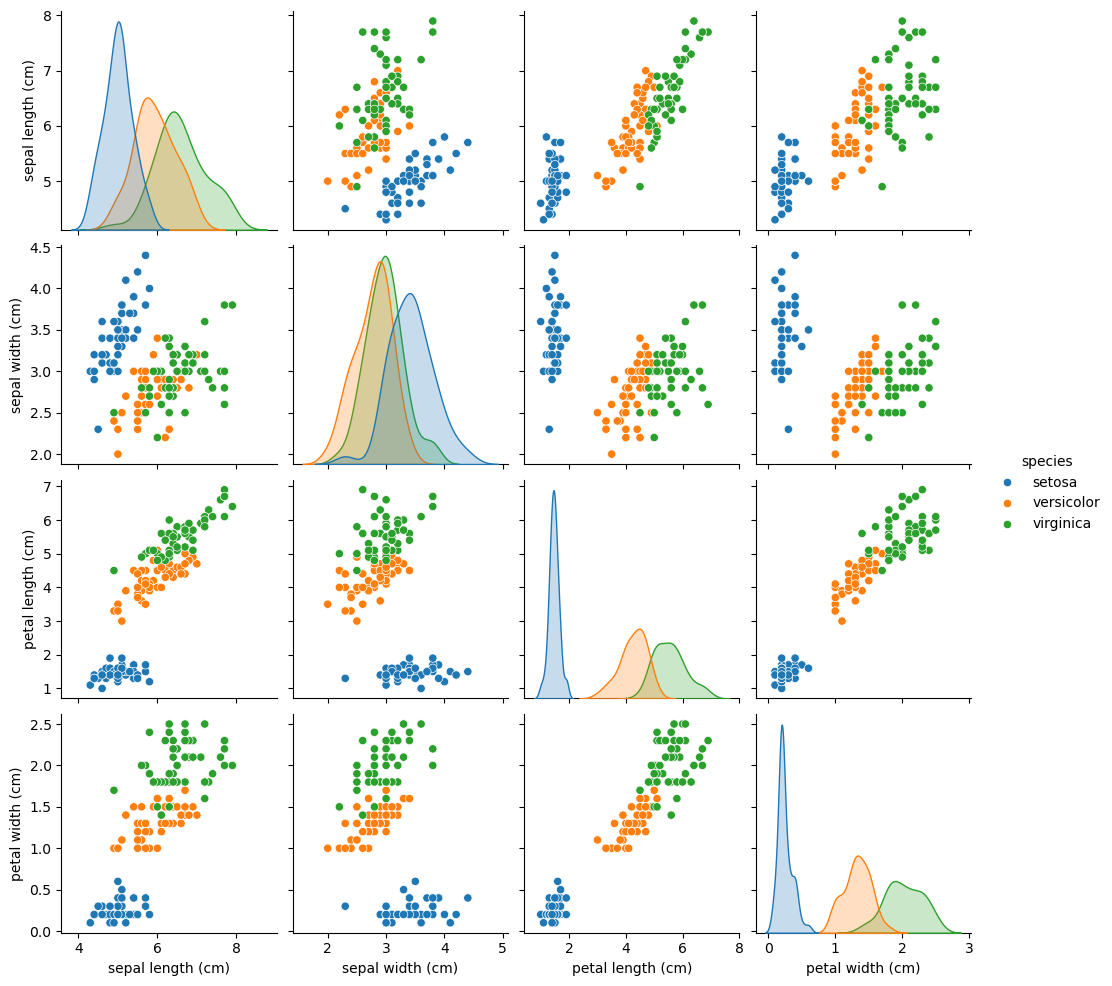

In [11]:
import seaborn as sns
sns.pairplot(df, hue="species")
plt.show()

**Observation:** _write what you notice — which species is easiest to separate, and which features help most?_

## Lab tasks — Hour 1
**L1.1** Print the first 10 and last 10 rows. Why are the species grouped together, and why does that matter when splitting data?

In [12]:
print(df.head(10))
print(df.tail(10))

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   
5                5.4               3.9                1.7               0.4   
6                4.6               3.4                1.4               0.3   
7                5.0               3.4                1.5               0.2   
8                4.4               2.9                1.4               0.2   
9                4.9               3.1                1.5               0.1   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  
5  setosa  
6  setosa  
7  setosa  
8  setosa  
9  setosa 

**L1.2** Find the minimum and maximum petal length for each species using `groupby`.

In [13]:
df.groupby("species", observed=True)["petal length (cm)"].agg(["min", "max"])

,min,max
species,,
setosa,1.0,1.9
versicolor,3.0,5.1
virginica,4.5,6.9


**L1.3** Scatter plot of sepal length vs sepal width coloured by species. Easier or harder to separate than with petal measurements?

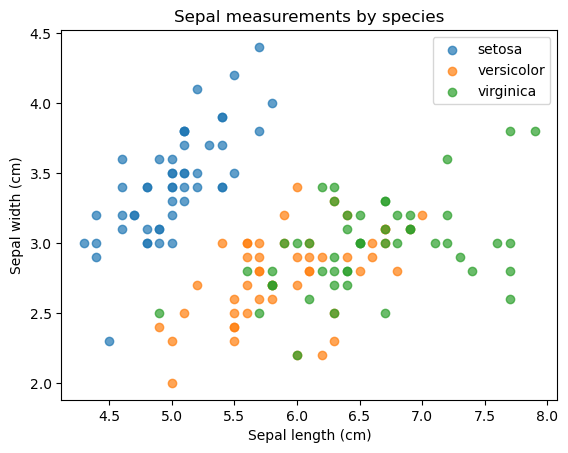

In [14]:
for species, group in df.groupby("species", observed=True):
    plt.scatter(group["sepal length (cm)"], group["sepal width (cm)"],
                label=species, color=colors[species], alpha=0.7)
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Sepal measurements by species")
plt.legend()
plt.show()

**L1.4** Write 3 observations about the data and say which two features you expect to matter most.

_Your answer:_

---
# Lab Hour 2 — Build a Classification Model
## Step 1: Separate features (X) and target (y)

In [15]:
X = df[iris.feature_names]
y = df["species"]
print(X.shape, y.shape)

(150, 4) (150,)


## Step 2: Train-test split

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% held back for testing
    random_state=42,    # same split every run
    stratify=y          # keep species proportions equal in both sets
)

print("Training:", X_train.shape, " Testing:", X_test.shape)
print(y_test.value_counts())

Training: (120, 4)  Testing: (30, 4)
species
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64


## Steps 3–4: Create and train the model

In [17]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

KNeighborsClassifier()

## Step 5: Predict on unseen data

In [18]:
y_pred = model.predict(X_test)
print(y_pred[:10])

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


## Step 6: Compare predictions with actual classes

In [19]:
results = pd.DataFrame({"actual": y_test.values, "predicted": y_pred})
results["correct"] = results["actual"] == results["predicted"]
print("Correct:", results["correct"].sum(), "out of", len(results))
results[~results["correct"]]   # only the mistakes

Correct: 30 out of 30


,actual,predicted,correct


## Lab tasks — Hour 2
**L2.1** Retrain with `n_neighbors=1` and `n_neighbors=25`. Record correct test predictions for K = 1, 5, 25.

In [20]:
for k in [1, 5, 25]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"K={k:>2}: {(m.predict(X_test) == y_test).sum()} / {len(y_test)} correct")

K= 1: 29 / 30 correct
K= 5: 30 / 30 correct
K=25: 28 / 30 correct


**L2.2** For each mistake, print the flower's four measurements. Do they look "in between" two species?

In [21]:
wrong = (y_pred != y_test.values)
X_test[wrong]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)


**L2.3** Split with `shuffle=False` and no `stratify`, then print `y_test.value_counts()`. Why is this a poor test set?

In [22]:
_, _, _, y_test_noshuffle = train_test_split(X, y, test_size=0.2, shuffle=False)
print(y_test_noshuffle.value_counts())

species
virginica     30
setosa         0
versicolor     0
Name: count, dtype: int64


_Your answer:_

**L2.4 (stretch)** Replace KNN with `DecisionTreeClassifier(random_state=42)`. What changed in your code?

In [23]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
print("Decision tree test accuracy:", tree.score(X_test, y_test))

Decision tree test accuracy: 0.9333333333333333


---
# Lab Hour 3 — Evaluate the Model and Experiment
## Step 1: Accuracy

In [24]:
from sklearn.metrics import accuracy_score

test_acc = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_acc:.2%}")
print(f"Same via model.score: {model.score(X_test, y_test):.2%}")

Test accuracy: 100.00%
Same via model.score: 100.00%


## Step 2: Confusion matrix
Rows = actual species, columns = predicted species. The diagonal is correct predictions.

[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


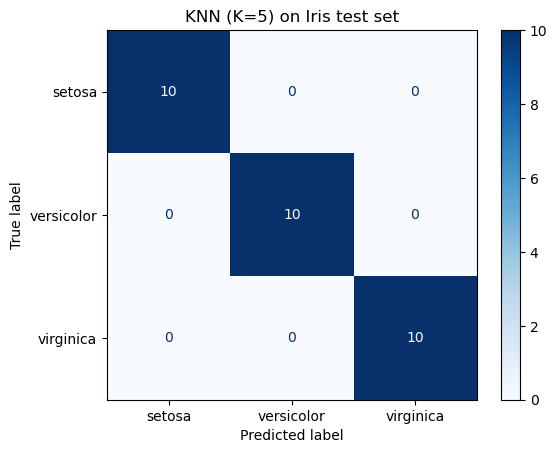

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(confusion_matrix(y_test, y_pred, labels=iris.target_names))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=iris.target_names, cmap="Blues")
plt.title("KNN (K=5) on Iris test set")
plt.show()

## Step 3: Classification report

In [26]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



## Step 4: Training vs testing accuracy

In [27]:
train_acc = model.score(X_train, y_train)
print(f"Training accuracy: {train_acc:.2%}")
print(f"Testing accuracy:  {test_acc:.2%}")
print(f"Gap:               {train_acc - test_acc:+.2%}")

Training accuracy: 96.67%
Testing accuracy:  100.00%
Gap:               -3.33%


In [28]:
for k in [1, 5, 15, 50]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"K={k:>2}  train={m.score(X_train, y_train):.2%}  test={m.score(X_test, y_test):.2%}")

K= 1  train=100.00%  test=96.67%
K= 5  train=96.67%  test=100.00%
K=15  train=97.50%  test=96.67%
K=50  train=90.00%  test=90.00%


## Step 5: Experiment with split ratios

In [29]:
rows = []
for ts in [0.1, 0.2, 0.3, 0.4, 0.5, 0.7]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=ts, random_state=42, stratify=y)
    m = KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr)
    rows.append({"test_size": ts, "train_rows": len(X_tr), "test_rows": len(X_te),
                 "train_acc": round(m.score(X_tr, y_tr), 3),
                 "test_acc": round(m.score(X_te, y_te), 3)})

split_results = pd.DataFrame(rows)
split_results

,test_size,train_rows,test_rows,train_acc,test_acc
0,0.1,135,15,0.963,1.000
1,0.2,120,30,0.967,1.000
2,0.3,105,45,0.971,0.978
3,0.4,90,60,0.956,0.933
4,0.5,75,75,0.960,0.947
5,0.7,45,105,0.956,0.981


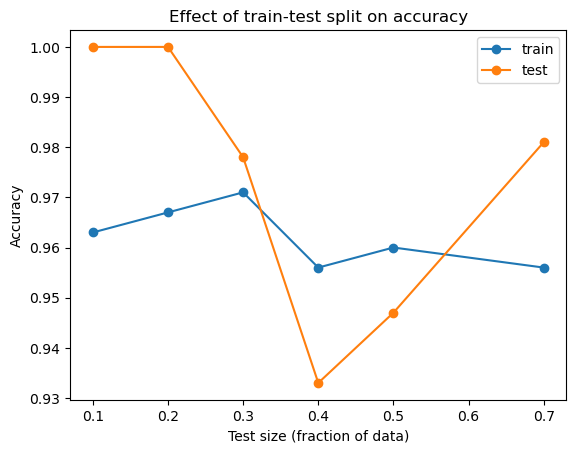

In [30]:
plt.plot(split_results["test_size"], split_results["train_acc"], marker="o", label="train")
plt.plot(split_results["test_size"], split_results["test_acc"], marker="o", label="test")
plt.xlabel("Test size (fraction of data)")
plt.ylabel("Accuracy")
plt.title("Effect of train-test split on accuracy")
plt.legend()
plt.show()

### Same ratio, different random splits

In [31]:
scores = []
for seed in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    scores.append(KNeighborsClassifier(n_neighbors=5).fit(X_tr, y_tr).score(X_te, y_te))

print("Min:", round(min(scores), 3), " Max:", round(max(scores), 3))
print(f"Mean: {np.mean(scores):.3f}   Std: {np.std(scores):.3f}")

Min: 0.933  Max: 1.0
Mean: 0.975   Std: 0.026


## Step 6: Predict new flowers

In [32]:
new_flowers = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2],
     [6.7, 3.0, 5.2, 2.3],
     [6.0, 2.8, 4.5, 1.4]],
    columns=iris.feature_names)

print(model.predict(new_flowers))
pd.DataFrame(model.predict_proba(new_flowers), columns=model.classes_).round(2)

['setosa' 'virginica' 'versicolor']


,setosa,versicolor,virginica
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,0.0,1.0,0.0


## Lab tasks — Hour 3
**L3.1** Which species has the lowest recall in your classification report? Why?

_Your answer:_

**L3.2** Fill in from your own run (use the K loop in Step 4):

| K | Training accuracy | Testing accuracy | Over-, under- or good fit? |
| --- | --- | --- | --- |
| 1 | | | |
| 5 | | | |
| 15 | | | |
| 50 | | | |

**L3.3** Invent measurements for a flower the model is unsure about (no species above 0.6 probability).

In [33]:
unsure = pd.DataFrame([[6.0, 2.9, 4.9, 1.6]], columns=iris.feature_names)
pd.DataFrame(model.predict_proba(unsure), columns=model.classes_).round(2)

,setosa,versicolor,virginica
0,0.0,0.4,0.6


**L3.4** Which test size would you choose for this dataset, and why?

_Your answer:_

---
# Observations and Conclusion
Answer in 5–8 sentences, using numbers from this notebook:

**How well does the model perform on unseen data, and what happens when the train-test split changes?**

_Your answer:_